# Interactive error visualisation — SwinNOx4 on PDEBench 2D reaction-diffusion

Interactive companion to the `pynop-eval` CLI driver (`pynop/eval/eval.py`): it runs the **same full autoregressive rollout** protocol (feed the first `input_steps` slices, then predict every remaining snapshot — the first prediction is teacher-forced on the ground-truth window, all subsequent ones consume the previous prediction), but instead of pooled metrics and static PNGs it keeps the **interactive plotly view**:

- one frame per predicted step with *Ground Truth / Prediction / Abs Error* panels, a play button and a scrub slider;
- independent color scales for the data (GT/Pred) and the error panel — each **fixed** (default: min/max over all displayed steps, so changes are comparable in time) or **adaptive** (each frame auto-scales to its own values);
- per-step RMSE / MAE / nRMSE curves along the trajectory.

The model is loaded from a training run directory (`model_config.json` + `training_config.json` + checkpoint), and trajectories come from the PDEBench HDF5 file through the unified dataloader — pointing this notebook at another run/dataset only requires changing `RUN_DIR`.


In [1]:
# Setup: imports, configuration, and reproducibility
import json
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import clear_output, display

from pynop.dataloader import get_dataset_class
from pynop.eval import build_eval_module, compute_step_errors, plot_interactive
from pynop.training.train import _load_weights_only  # internal helper used by the eval driver

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device} | torch {torch.__version__}")


Device: cuda | torch 2.14.1+cu130


## Model and data

The run directory holds everything needed: the exact configs used for training, `run_info.json` (stored train/val IDs, phase) and the checkpoints. The evaluation trajectories are the **validation split of that run** — by construction never used for training.


In [2]:
# Configuration: run directory, checkpoint, phase
RUN_DIR = Path("/run/media/jlux/SSD2/PDETraining/PDEBENCH/pretraining/SwinNOx4")
CHECKPOINT_NAME = "last.ckpt"  # or one of the best_* checkpoints listed below

run_subdirs = sorted(RUN_DIR.glob("10steps_*"))
assert len(run_subdirs) == 1, f"Expected a single run dir in {RUN_DIR}, found: {[p.name for p in run_subdirs]}"
run_dir = run_subdirs[0]

model_cfg = json.loads((run_dir / "model_config.json").read_text())
training_cfg = json.loads((run_dir / "training_config.json").read_text())
run_info = json.loads((run_dir / "run_info.json").read_text())
phase_name = run_info.get("phase", "pretraining")  # phase this checkpoint was trained in

print(f"Run dir     : {run_dir}")
print(f"Model       : {model_cfg['name']} ({model_cfg['model']}) — {len(run_info.get('train_ids', []))} train / {len(run_info.get('val_ids', []))} val sims")
print(f"Phase       : {phase_name}")
print(f"Checkpoints : {[p.name for p in sorted(run_dir.glob('*.ckpt'))]}")


Run dir     : /run/media/jlux/SSD2/PDETraining/PDEBENCH/pretraining/SwinNOx4/10steps_20261029-173754
Model       : SwinNOx4 (SwinNO) — 36 train / 4 val sims
Phase       : pretraining
Checkpoints : ['best_RMSE-v1.ckpt', 'best_RMSE.ckpt', 'best_val_RMSE-v1.ckpt', 'best_val_RMSE.ckpt', 'last.ckpt']


In [3]:
# Build the inference wrapper and load the checkpoint weights
lightning_model, model_name = build_eval_module(model_cfg, training_cfg, phase_name)
_load_weights_only(lightning_model.model, run_dir / CHECKPOINT_NAME)
n_params = sum(p.numel() for p in lightning_model.model.parameters())

input_steps = int(training_cfg["input_steps"])
phase_cfg = training_cfg[phase_name]
min_id = int(phase_cfg.get("min_id", 0))
max_id = phase_cfg.get("max_id")  # None = end of trajectory

lightning_model.eval().to(device)
print(f"{model_name}: {type(lightning_model.model).__name__}, {n_params / 1e6:.2f} M params on '{device}'")
print(f"Rollout: {input_steps} input slices, t in [{min_id}, {max_id}) — checkpoint '{CHECKPOINT_NAME}' loaded")


predict_derivative: True
Derivative loss: NormalizedTimeDerivativeMSE(), with weight: 0.0
Weights loaded from /run/media/jlux/SSD2/PDETraining/PDEBENCH/pretraining/SwinNOx4/10steps_20261029-173754/last.ckpt (55 tensors).
SwinNOx4: SwinNO, 2.25 M params on 'cuda'
Rollout: 10 input slices, t in [0, 50) — checkpoint 'last.ckpt' loaded


In [4]:
# Evaluation trajectories: validation split of the run
ds_cfg = training_cfg["dataset"]
shift, scale = float(ds_cfg.get("shift", 0.0)), float(ds_cfg.get("scale", 1.0))
val_ids = list(run_info["val_ids"])

reader = get_dataset_class(str(ds_cfg["type"]).lower())(
    ds_cfg["path"],
    indexes=val_ids,
    load_in_ram=False,
    min_id=min_id,
    max_id=max_id,
    shift=shift,
    scale=scale,
)
print(f"Dataset: {ds_cfg['type']} — {ds_cfg['path']}")
for sid in val_ids:
    L_total = int(reader.sample_lengths[sid])
    end = min(int(max_id), L_total) if max_id is not None else L_total  # phase time range crop
    L = end - min_id
    print(f"  sim {sid}: {L} frames in [{min_id}, {max_id}) -> {max(L - input_steps, 0)} predictions")


PDEBenchDataSet initialized with 4 simulations.
Total unrolled windows: 20
Status: Disk mode.
Dataset: pdebench — /run/media/jlux/SSD2/datasets/pdebench/2d_reaction_diffusion/133017.hdf5
  sim 0596: 50 frames in [0, 50) -> 40 predictions
  sim 0720: 50 frames in [0, 50) -> 40 predictions
  sim 0053: 50 frames in [0, 50) -> 40 predictions
  sim 0426: 50 frames in [0, 50) -> 40 predictions


## Rollout and per-step errors

`rollout(sid)` reproduces the `pynop-eval` protocol for one trajectory: the first prediction is teacher-forced on the ground-truth window, then every next snapshot consumes the previous **prediction** (rolling window). The k-th prediction targets frame `min_id + input_steps + k`.


In [5]:
# Full autoregressive rollout of one trajectory (same protocol as pynop-eval)
def rollout(sid):
    """Roll out simulation ``sid`` and return stacked predictions/targets."""
    fields = reader.load_trajectory(sid, min_id, max_id).unsqueeze(0).to(device)  # (1, T, C, H, W)
    time_idx = torch.full((1,), float(min_id), device=device)
    cond = reader.load_conditioning(sid)
    if cond is not None:
        cond = cond.unsqueeze(0).to(device)
    with torch.no_grad():
        res = lightning_model._rollout(fields, time_idx, cond, training=False, store_fields=True)

    def _stack_steps(step_list):
        # per-step (B=1, C, H, W) tensors -> (T_pred, C, H, W)
        return torch.stack(step_list).reshape(-1, *step_list[0].shape[1:]).cpu()

    return {
        "pred": _stack_steps(res["preds"]),   # (T_pred, C, H, W)
        "gt": _stack_steps(res["targets"]),
        "n_predictions": int(res["num_predictions"]),
    }


def time_labels(n_pred):
    """Absolute frame index targeted by each prediction."""
    return [min_id + input_steps + k for k in range(n_pred)]


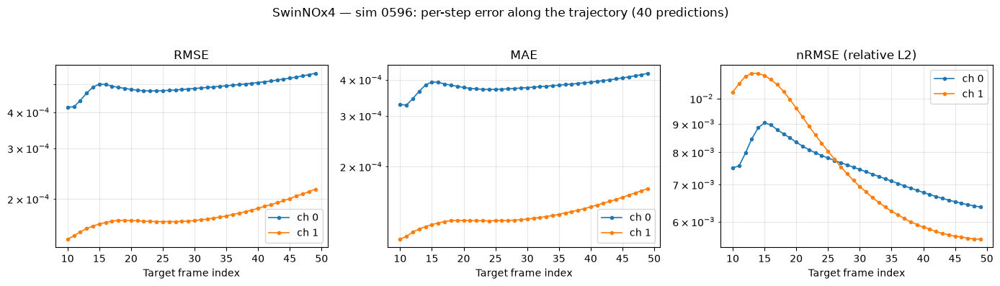

Mean RMSE over all steps: ch 0 = 4.916e-04, ch 1 = 1.754e-04


In [6]:
# Per-step error curves along the trajectory (default simulation)
DEFAULT_SIM = val_ids[0]
res = rollout(DEFAULT_SIM)
t = time_labels(res["n_predictions"])


def plot_step_curves(r, t, suptitle):
    """RMSE / MAE / nRMSE per step and channel (log scale), like the eval PNGs."""
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ch in range(r["pred"].shape[1]):
        m = compute_step_errors(r["pred"], r["gt"], channel_idx=ch)
        for ax, key, label in zip(axes, ("rmse", "mae", "nrmse"), ("RMSE", "MAE", "nRMSE (relative L2)")):
            ax.plot(t, m[key], marker="o", ms=3, lw=1.2, label=f"ch {ch}")
            ax.set_yscale("log")
            ax.grid(True, which="both", alpha=0.3)
    for ax, label in zip(axes, ("RMSE", "MAE", "nRMSE (relative L2)")):
        ax.set_title(label)
        ax.set_xlabel("Target frame index")
        ax.legend()
    fig.suptitle(suptitle)
    plt.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()


plot_step_curves(res, t, f"{model_name} — sim {DEFAULT_SIM}: per-step error along the trajectory ({res['n_predictions']} predictions)")

means = ", ".join(
    f"ch {c} = {compute_step_errors(res['pred'], res['gt'], channel_idx=c)['rmse'].mean():.3e}"
    for c in range(res["pred"].shape[1])
)
print(f"Mean RMSE over all steps: {means}")


## Interactive view

The animated figure shows one frame per predicted step with three panels — GT and Prediction share a **single data colorbar** (drawn on the Prediction panel) and the Abs Error panel has its own, so no colorbars overlap. Scale semantics of `pynop.eval.visualisation.plot_interactive`:

| argument | `"fixed"` (default) | `"adaptive"` |
|---|---|---|
| `data_scale` | one GT/Pred range for all steps — min/max of GT+Pred over every displayed step | each frame auto-scales to its own data |
| `error_scale` | one error range for all steps — min/max of the absolute error over every displayed step | each frame auto-scales to its own error |

Explicit bounds can override either mode with `data_vmin`/`data_vmax` and `error_vmin`/`error_vmax`. Drag the **scrub slider** (or press Play) to move through time — the title shows that step's **RMSE / MAE / nRMSE**.


In [7]:
# Interactive GT / Prediction / Abs Error view (play button + scrub slider)
CHANNEL = 1            # field to display (0 or 1)
DATA_SCALE = "adaptive"   # "fixed" | "adaptive"
ERROR_SCALE = "fixed"  # "fixed" | "adaptive"

plot_interactive(
    res["pred"],
    res["gt"],
    channel_idx=CHANNEL,
    data_scale=DATA_SCALE,
    error_scale=ERROR_SCALE,
    step_labels=t,
)


In [8]:
# Interactive explorer: pick simulation / channel / scale modes.
# Each change re-rolls out the selected trajectory (cached) and redraws the
# interactive figure **in place** — clear_output() + redisplay replaces the
# previous figure instead of stacking a new one below the controls.
sim_dd = widgets.Dropdown(options=val_ids, value=DEFAULT_SIM, description="Simulation", layout=widgets.Layout(width="200px"))
ch_dd = widgets.Dropdown(options=list(range(res["pred"].shape[1])), value=CHANNEL, description="Channel")
ds_dd = widgets.Dropdown(options=["fixed", "adaptive"], value=DATA_SCALE, description="Data scale")
es_dd = widgets.Dropdown(options=["fixed", "adaptive"], value=ERROR_SCALE, description="Error scale")
status_lbl = widgets.Label(value="", layout=widgets.Layout(width="640px"))
controls = widgets.VBox([widgets.HBox([sim_dd, ch_dd, ds_dd, es_dd]), status_lbl])

_cache: dict = {DEFAULT_SIM: res}  # reuse the rollout computed above


def update(*_):
    """Re-roll out (cached) and redraw the interactive figure in place."""
    sid = sim_dd.value
    if sid not in _cache:
        status_lbl.value = f"Rolling out simulation {sid} ..."
        clear_output(wait=True)
        display(controls)  # show progress while the rollout runs
        _cache[sid] = rollout(sid)
    r = _cache[sid]
    t = time_labels(r["n_predictions"])
    status_lbl.value = (
        f"Simulation {sid} | channel {ch_dd.value} | data scale: {ds_dd.value} | error scale: {es_dd.value}"
    )
    clear_output(wait=True)
    display(controls)
    display(
        plot_interactive(
            r["pred"],
            r["gt"],
            channel_idx=ch_dd.value,
            data_scale=ds_dd.value,
            error_scale=es_dd.value,
            step_labels=t,
        )
    )


for w in (sim_dd, ch_dd, ds_dd, es_dd):
    w.observe(update, names="value")

update()  # initial render (also captured when the notebook is executed statically)

## Notes

- **Pointing at another run**: change `RUN_DIR` in the configuration cell — model class, params, dataset path, phase and validation IDs are all read from the run's own JSON files. Any checkpoint of the run can be selected via `CHECKPOINT_NAME`.
- **Scales**: with `"fixed"` scales the color range is constant over time (default: min/max over every displayed step), which makes temporal changes directly comparable; `"adaptive"` re-scales each frame and reveals local structure at the cost of comparability. The data and error scales are independent — e.g. `data_scale="fixed", error_scale="adaptive"` keeps GT/Pred stable while letting the error panel adapt to each step's magnitude.
- **Protocol**: identical to `pynop-eval` (see `pynop/eval/eval.py`) — first prediction teacher-forced, then autoregressive; all metrics are computed in model space (after the dataset normalization).
- **Explorer**: changing any dropdown re-renders the curves + interactive figure below the controls (rollouts are cached per simulation, so only new trajectories cost a forward pass).
